## Desafio

Trabajaremos con una base de datos sobre clientes morosos de un banco. Dentro de ésta se registran las siguientes observaciones:

- `default`​: Variable Binaria. Registra si el cliente entró en morosidad o no.
- `income​`: Ingreso promedio declarado por el cliente.
- `balance​`: total del saldo en la cuenta de crédito.
- `student​`: Variable binaria. Registra si el cliente es estudiante o no.

### Ejercicio 1: Preparación de ambiente de trabajo

- Importe los módulos básicos para el análisis de datos.
- Importe las clases `​LabelEncoder​`, `​StandardScaler` y `​LabelBinarizer` de `preprocessing`.
- Importe las funciones `​train_test_split​` y `​cross_val_score​` de `​model_selection`
- Importe la función `​classification_report​` de `​metrics​`.
- Importe las clases `​LinearDiscriminantAnalysis` y `QuadraticDiscriminantAnalysis​`.
- Agregue la base de datos en el ambiente de trabajo.
- Inspeccione la distribución de cada atributo.

### Ejercicio 2: Modelo base

- Recuerde que los modelos de `​sklearn` no soportan datos que no sean numéricos. Transforme los atributos pertinentes con `​LabelEncoder​`.
- Genere muestras de validación y entrenamiento, reservando un 33% de los datos como
validación.
- Genere un modelo con `​LinearDiscriminantAnalysis` sin modificar los hiper parámetros. Genere métricas de evaluación utilizando `​classification_report​`.
- Comente sobre cuál es el desempeño del modelo en cada clase, así como en general.

### Ejercicio 3: Refactorización 1 - información a priori

- Dado que trabajamos con modelos generativos, podemos incluir información exógena. Para este caso agregaremos dos distribuciones:
    + Asumamos que hay un 50/50 de morosos y no morosos.
    + Asumamos que hay un 60/40 de morosos y no morosos.
- Por cada modelo, reporte las métricas de clasificación.

### Ejercicio 4: Refactorización 2 - oversampling

#### Digresión: Synthetic Over(Under)Sampling

- Por lo general podemos intentar aliviar el problema del desbalance de clases mediante la ponderación dentro del algoritmo. Otra alternativa es el muestreo con reemplazo dentro de los conjuntos de entrenamiento. Estos métodos clásicos se conocen como **Oversampling** cuando repetimos registros aleatorios de la clase minoritaria, y **Undersampling​** cuando eliminamos aleatoriamente registros de la clase mayoritaria.

- Un contratiempo de estos métodos clásicos es que pueden replicar información sesgada que afecte el desempeño de generalización del modelo. Si los datos son malos, estaremos replicando estas fallas.

- Otra solución es generar ejemplos de entrenamiento sintéticos mediante el entrenamiento de ejemplos de la clase minoritaria. A grandes rasgos la solución funciona de la siguiente forma: En función a un subconjunto de datos correspondientes a la clase minoritaria, entrenamos algún modelo no supervisado o generativo como Naive Bayes, KMeans o KNearestNeighbors para generar representaciones sintéticas de
los datos **​en el espacio de atributos de la clase específica** mediante $x_\text{nuevo−ejemplo} = x_i + \lambda(x_{zi} − x_i)$ es un ejemplo de entrenamiento de la clase minoritaria y $\lambda$ es un parámetro de interpolación aleatorio $\lambda ~ \text{Uniforme}(0, 1)$.

- Uno de los problemas más graves de esta base de datos, s el fuerte desbalance entre clases. Ahora generaremos observaciones sintéticas mediante SMOTE (Synthetic Minority Oversampling Technique). Para ello, debemos agregar el paquete a nuestro ambiente virtual. En nuestro terminal agregamos `​conda install -c conda-forge imbalanced-learn`​. Incorpore SMOTE en el ambiente de trabajo con la siguiente sintáxis `​from​ imblearn.over_sampling ​import​ SMOTE`​.

- Para implementar oversampling, debemos generar nuevos objetos que representan nuestra muestra de entrenamiento incrementada artificialmente. Para ello implemente la siguiente sintaxis:

```python	
from​ imblearn.over_sampling ​import​ SMOTE
# Instanciamos la clase
oversampler = SMOTE(random_state=​11238​, ratio=​'minority'​)
# generamos el eversampling de la matriz de entrenamiento y
X_train_oversamp, y_train_oversamp = oversampler.fit_resample(X_train, y_train)
```	
- Vuelva a entrenar el modelo con los datos aumentados de forma artificial y comente sobre su desempeño.

### Ejercicio 5: Refactorización 3 - QDA

- Por último, implemente un modelo `​QuadraticDiscriminantAnalysis` con los datos aumentados artificialmente. Genere las métricas de desempeño.

- Comente a grandes rasgos sobre el mejor modelo en su capacidad predictiva.


# Preparación del ambiente:

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler, LabelBinarizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from imblearn.over_sampling import SMOTE

# Carga de la base de datos:

C:\Users\lukas\AppData\Local\Temp\ipykernel_7372\1496286138.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='default', ax=axes[0, 0], palette="Set2")
C:\Users\lukas\AppData\Local\Temp\ipykernel_7372\1496286138.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='student', ax=axes[0, 1], palette="Set2")


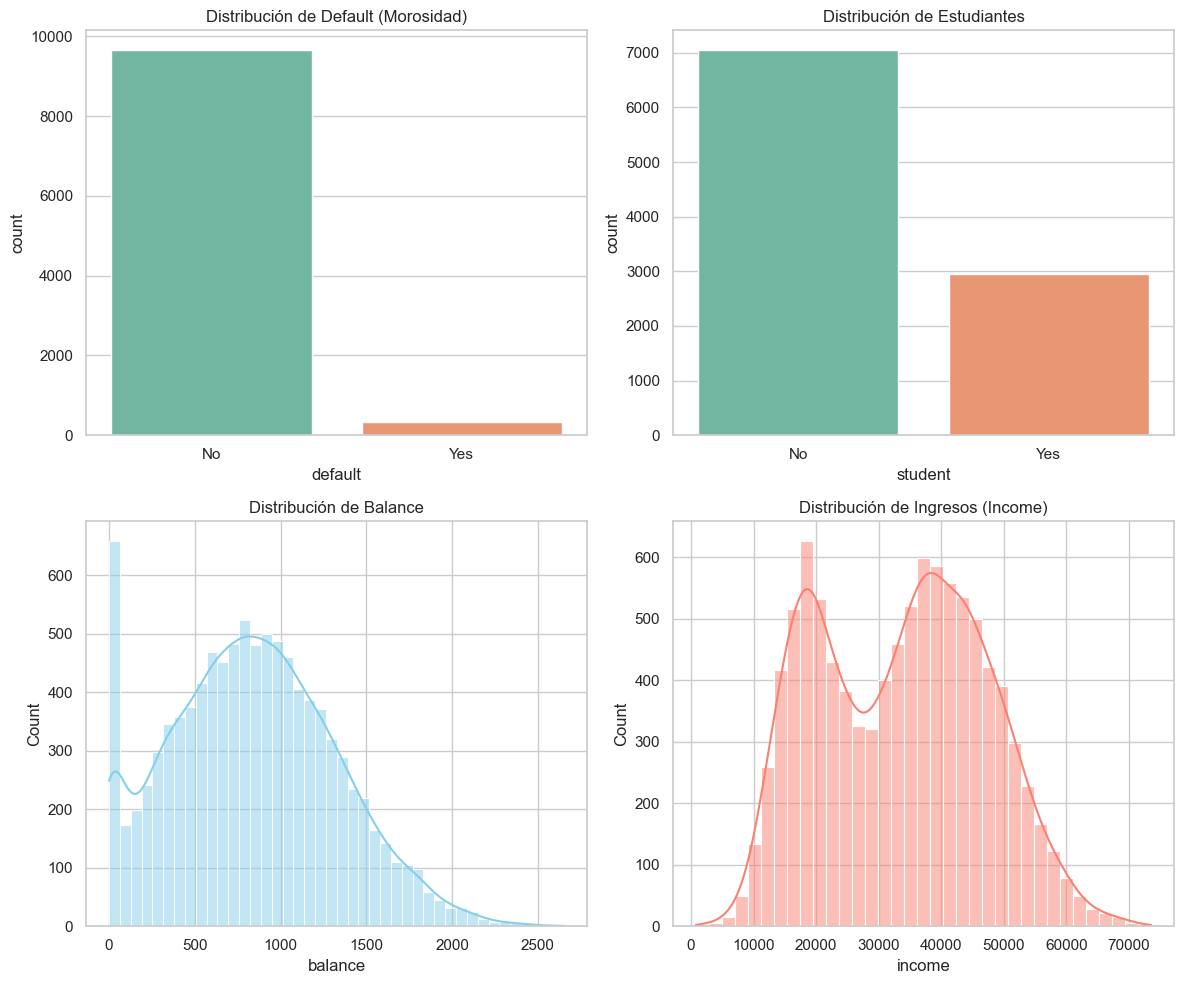

In [ ]:
#Carga de la base de datos
df = pd.read_csv('default_credit.csv')

#Eliminamos la columna 'index'
df = df.drop(columns=['index'])

#Visualización la distribución de la base de datos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

#Variables categóricas (usamos countplot)
sns.countplot(data=df, x='default', ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title('Distribución de Default (Morosidad)')

sns.countplot(data=df, x='student', ax=axes[0, 1], palette="Set2")
axes[0, 1].set_title('Distribución de Estudiantes')

#Variables numéricas (usamos histplot)
sns.histplot(data=df, x='balance', kde=True, ax=axes[1, 0], color="skyblue")
axes[1, 0].set_title('Distribución de Balance')

sns.histplot(data=df, x='income', kde=True, ax=axes[1, 1], color="salmon")
axes[1, 1].set_title('Distribución de Ingresos (Income)')

plt.tight_layout()
plt.show()

# Modelo base:

In [4]:
#Transformamos los datos no numéricos
encoder = LabelEncoder()
df['default'] = encoder.fit_transform(df['default']) # No = 0, Yes = 1
df['student'] = encoder.fit_transform(df['student']) # No = 0, Yes = 1

#Defininimos la matriz de atributos y vector objetivo
X = df.drop(columns=['default'])
y = df['default']

#Generarmos muestras de entrenamiento y validación, 33% para pruebas y 67% entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

#Generar y evaluar modelo LDA base
lda_base = LinearDiscriminantAnalysis()
lda_base.fit(X_train, y_train)
y_pred_base = lda_base.predict(X_test)

print("REPORTE LDA BASE")
print(classification_report(y_test, y_pred_base))

REPORTE LDA BASE
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      3190
           1       0.79      0.25      0.38       110

    accuracy                           0.97      3300
   macro avg       0.88      0.62      0.68      3300
weighted avg       0.97      0.97      0.97      3300



**Comentario:**

El modelo original presentará una precisión general superior al 96%. Sin embargo, esto es provocado por el desbalance de clases. El recall de la clase 1 (morosos), es muy bajo. El modelo es excelente prediciendo quién no entrará en default, pero muy deficiente identificando a los verdaderos morosos.

# Refactorización:

In [6]:
#Asumimos 50/50 de morosos y no morosos
lda_prior_50 = LinearDiscriminantAnalysis(priors=[0.5, 0.5])
lda_prior_50.fit(X_train, y_train)
y_pred_50 = lda_prior_50.predict(X_test)

print("\nREPORTE LDA (Priors 50/50)")
print(classification_report(y_test, y_pred_50))

#Asumimos 60/40 de morosos (1) y no morosos (0) -> priors = [0.4, 0.6]
lda_prior_60_40 = LinearDiscriminantAnalysis(priors=[0.4, 0.6])
lda_prior_60_40.fit(X_train, y_train)
y_pred_60_40 = lda_prior_60_40.predict(X_test)

print("\nREPORTE LDA (Priors 40(No) / 60(Sí))")
print(classification_report(y_test, y_pred_60_40))


REPORTE LDA (Priors 50/50)
              precision    recall  f1-score   support

           0       0.99      0.85      0.92      3190
           1       0.17      0.87      0.28       110

    accuracy                           0.85      3300
   macro avg       0.58      0.86      0.60      3300
weighted avg       0.97      0.85      0.89      3300


REPORTE LDA (Priors 40(No) / 60(Sí))
              precision    recall  f1-score   support

           0       1.00      0.80      0.89      3190
           1       0.14      0.94      0.24       110

    accuracy                           0.80      3300
   macro avg       0.57      0.87      0.56      3300
weighted avg       0.97      0.80      0.86      3300



# Refactorización 2

In [ ]:
#Refactorización 2, Oversampling

#Instanciamos la clase SMOTE (usamos sampling_strategy en lugar del obsoleto 'ratio')
oversampler = SMOTE(random_state=11238, sampling_strategy='minority')

#Generamos el oversampling de la matriz de entrenamiento
X_train_oversamp, y_train_oversamp = oversampler.fit_resample(X_train, y_train)

#Entrenamos el modelo LDA con datos aumentados
lda_smote = LinearDiscriminantAnalysis()
lda_smote.fit(X_train_oversamp, y_train_oversamp)
y_pred_smote = lda_smote.predict(X_test)

print("\nREPORTE LDA (Con SMOTE)")
print(classification_report(y_test, y_pred_smote))


REPORTE LDA (Con SMOTE)
              precision    recall  f1-score   support

           0       1.00      0.85      0.92      3190
           1       0.17      0.88      0.28       110

    accuracy                           0.85      3300
   macro avg       0.58      0.87      0.60      3300
weighted avg       0.97      0.85      0.90      3300



**Comentarios:**
Desempeño con Oversampling:
A diferencia del ajuste de priors, SMOTE agrega datos sintéticos generados en el espacio de características. El modelo entrenado con SMOTE equilibrará mucho mejor las métricas de la clase minoritaria sin ser tan destructivo con la clase mayoritaria como lo fue el prior exagerado de 60/40.

# Refactorización 3

In [15]:
#EJERCICIO 5: Refactorización 3 - QDA

#Entrenamos un modelo QDA con los datos aumentados artificialmente
qda_smote = QuadraticDiscriminantAnalysis()
qda_smote.fit(X_train_oversamp, y_train_oversamp)
y_pred_qda = qda_smote.predict(X_test)

print("\nREPORTE QDA (Con SMOTE)")
print(classification_report(y_test, y_pred_qda))


REPORTE QDA (Con SMOTE)
              precision    recall  f1-score   support

           0       0.99      0.88      0.93      3190
           1       0.19      0.85      0.32       110

    accuracy                           0.88      3300
   macro avg       0.59      0.86      0.62      3300
weighted avg       0.97      0.88      0.91      3300

